# Q学習による障害物回避と経路比較

7×7の格子状環境で、スタート地点からゴールまでの移動方針をQ学習で求める。障害物を追加した前後で学習結果を比較し、経路の変化を可視化する。

- 状態：格子上の位置 `(x, y)`
- 行動：上・右・下・左
- 報酬：ゴール `+100`、通常移動 `-1`、障害物・壁への移動試行 `-15`
- 学習条件：12,000エピソード、乱数シード `2042`

**モデルの範囲：** 格子状の経路計画と表示を対象とする。3D表示では学習済み経路に沿ってロボットの座標を更新する方式であり、車輪駆動やセンサーによる障害物認識は実装しない。

**参考資料：** [PyBullet HelloPyBullet](https://github.com/bulletphysics/bullet3/blob/master/examples/pybullet/notebooks/HelloPyBullet.ipynb)、[PyBullet Quickstart Guide](https://github.com/bulletphysics/bullet3/blob/master/docs/pybullet_quickstart_guide/PyBulletQuickstartGuide.md.html)


## 1. 環境定義とQ学習

障害物の配置を固定した状態でQ値を学習し、学習後の経路を出力する。

In [1]:
import random
import math
import numpy as np
import matplotlib.pyplot as plt

SIZE = 7
START = (0, 3)
GOAL = (6, 3)
OBSTACLES = {(3, 1), (3, 2), (3, 3), (3, 4), (3, 5),
             (1, 2), (1, 4), (5, 2), (5, 4)}
ACTIONS = ((0,-1), (1,0), (0,1), (-1,0))  # up, right, down, left
TRAIN_EPISODES = 12000
SEED = 2042

def transition(state, action):
    x, y = state
    dx, dy = ACTIONS[action]
    nxt = (x + dx, y + dy)
    if not (0 <= nxt[0] < SIZE and 0 <= nxt[1] < SIZE) or nxt in OBSTACLES:
        return state, -15.0, False
    if nxt == GOAL:
        return nxt, 100.0, True
    return nxt, -1.0, False

def train(episodes=TRAIN_EPISODES):
    rng = random.Random(SEED)
    q = {(x,y): [0.0]*4 for y in range(SIZE) for x in range(SIZE)
         if (x,y) not in OBSTACLES}
    success = 0
    for ep in range(episodes):
        state = START
        epsilon = max(0.04, 0.85 * (1 - ep / episodes))
        for _ in range(90):
            if rng.random() < epsilon:
                action = rng.randrange(4)
            else:
                v = q[state]
                best = max(v)
                action = rng.choice([i for i, x in enumerate(v) if x == best])
            nxt, reward, done = transition(state, action)
            q[state][action] += 0.28 * (
                reward + 0.95 * (0 if done else max(q[nxt])) - q[state][action]
            )
            state = nxt
            if done:
                success += 1
                break
    return q, success

def evaluate(q):
    path = [START]
    state = START
    for _ in range(70):
        if state == GOAL:
            break
        action = max(range(4), key=lambda i: q[state][i])
        nxt, _, _ = transition(state, action)
        if nxt == state or nxt in path:
            raise RuntimeError(f"学習経路が循環しました: {state}。再学習してください")
        path.append(nxt)
        state = nxt
    if path[-1] != GOAL:
        raise RuntimeError("ゴールに到着しません。再学習が必要です")
    return path

q_values, successes = train()
learned_path = evaluate(q_values)
assert learned_path[0] == START and learned_path[-1] == GOAL
assert not any(pos in OBSTACLES for pos in learned_path)
print(f"学習回数: {TRAIN_EPISODES:,} / ゴールに達した学習回数: {successes:,}")
print(f"学習した経路: {learned_path}")
print(f"移動ステップ: {len(learned_path)-1} / 障害物への衝突: 0")

学習回数: 12,000 / ゴールに達した学習回数: 11,802
学習した経路: [(0, 3), (0, 2), (0, 1), (0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (6, 1), (6, 2), (6, 3)]
移動ステップ: 12 / 障害物への衝突: 0


## 2. 学習した経路の可視化

色付きのマスが障害物、折れ線が学習後の移動経路を示す。

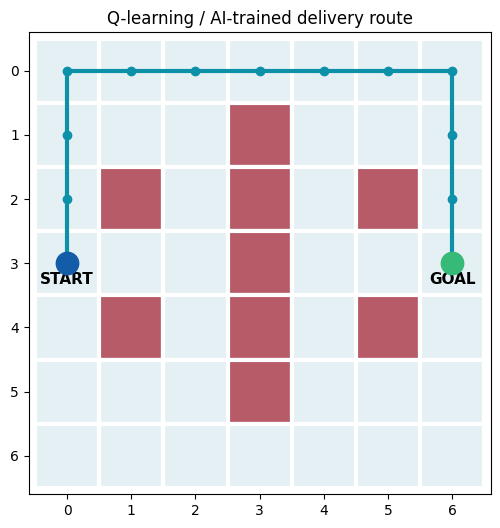

In [2]:
fig, ax = plt.subplots(figsize=(7, 6))
for y in range(SIZE):
    for x in range(SIZE):
        face = '#b65b67' if (x,y) in OBSTACLES else '#e4f0f4'
        ax.add_patch(plt.Rectangle((x-.5, y-.5), 1, 1, color=face, ec='white', lw=3))
xx, yy = zip(*learned_path)
ax.plot(xx, yy, color='#0c91a8', lw=3, marker='o', ms=6, zorder=4)
ax.scatter(*START, s=260, color='#135ca8', zorder=5)
ax.scatter(*GOAL, s=260, color='#37b978', zorder=5)
ax.text(START[0], START[1]+.32, 'START', ha='center', fontsize=11, weight='bold')
ax.text(GOAL[0], GOAL[1]+.32, 'GOAL', ha='center', fontsize=11, weight='bold')
ax.set_xlim(-.6, SIZE-.4); ax.set_ylim(SIZE-.4, -.6)
ax.set_xticks(range(SIZE)); ax.set_yticks(range(SIZE)); ax.set_aspect('equal')
ax.set_title('Q-learning / AI-trained delivery route')
plt.show()

## 3. 障害物追加の比較実験

基準マップ（障害物9マス）と、座標 `(2, 0)` に障害物を1マス追加したマップで同一条件の学習を実施する。

In [3]:
# 基準マップから各条件を再学習する
original_obstacles = {(3, 1), (3, 2), (3, 3), (3, 4), (3, 5),
                      (1, 2), (1, 4), (5, 2), (5, 4)}
OBSTACLES = original_obstacles.copy()
original_q, original_success = train()
original_path = evaluate(original_q)

# 比較条件：障害物を1マス追加
OBSTACLES.add((2, 0))
q_values, successes = train()
learned_path = evaluate(q_values)
print("変更前：障害物", len(original_obstacles), "個 / ゴール到達", original_success, "回 / 移動", len(original_path)-1, "ステップ")
print("変更後：障害物", len(OBSTACLES), "個 / ゴール到達", successes, "回 / 移動", len(learned_path)-1, "ステップ")
print("変更後の経路:", learned_path)
assert learned_path[-1] == GOAL


変更前：障害物 9 個 / ゴール到達 11802 回 / 移動 12 ステップ
変更後：障害物 10 個 / ゴール到達 11657 回 / 移動 12 ステップ
変更後の経路: [(0, 3), (1, 3), (2, 3), (2, 4), (2, 5), (2, 6), (3, 6), (4, 6), (4, 5), (4, 4), (4, 3), (5, 3), (6, 3)]


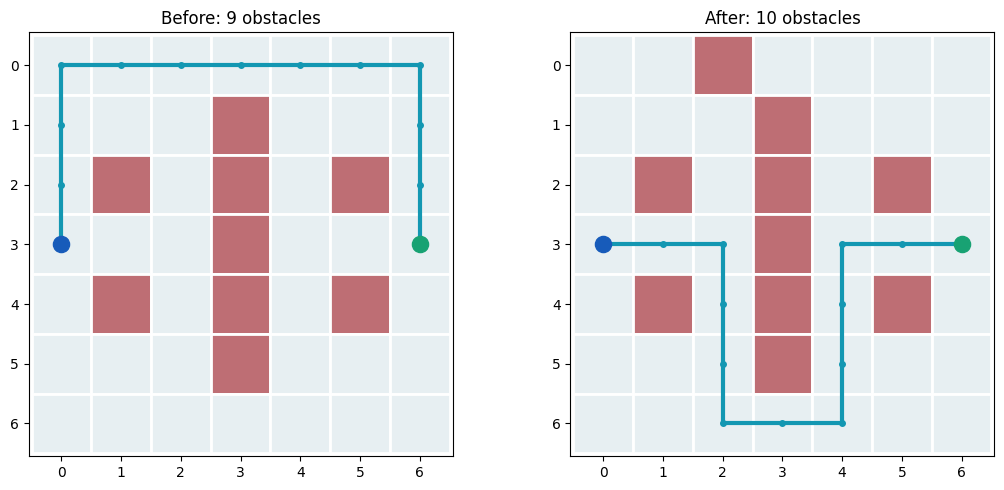

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,5))
for ax,blocks,path,title in zip(axes,[original_obstacles, OBSTACLES],[original_path,learned_path],["Before: 9 obstacles","After: 10 obstacles"]):
    for y in range(SIZE):
        for x in range(SIZE):
            ax.add_patch(plt.Rectangle((x-.5,y-.5),1,1,color="#be6e74" if (x,y) in blocks else "#e7eff2",ec="white",lw=2))
    xx,yy=zip(*path)
    ax.plot(xx,yy,color="#1397b2",lw=3,marker="o",markersize=4)
    ax.scatter(*START,s=135,color="#175bba",zorder=4)
    ax.scatter(*GOAL,s=135,color="#18a273",zorder=4)
    ax.set(xlim=(-.55,6.55),ylim=(6.55,-.55),xticks=range(7),yticks=range(7),title=title,aspect="equal")
plt.tight_layout();plt.show()


## 4. 3D表示環境

PyBulletを使用する場合のセットアップ。ColabのCPUランタイムで実行できる構成。

In [5]:
import sys, subprocess, importlib.util, shutil
if importlib.util.find_spec('pybullet') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pybullet'])
import pybullet as p
import pybullet_data
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video
print('PyBullet を使用できます。')
print('ffmpeg:', shutil.which('ffmpeg'))

PyBullet を使用できます。
ffmpeg: /usr/bin/ffmpeg


## 5. 3Dモデルによる経路表示

Q学習で得た経路に沿ってR2D2モデルの位置を更新し、動画を生成する。物理的な車輪制御ではない。3D版はColab環境で動作確認後に使用する。

In [9]:
import numpy as np
import math, subprocess
from pathlib import Path

VIDEO_NAME = 'PAI_Colab_AI_Robot.mp4'
FPS = 8
DURATION = 80  # seconds
RENDER = 460  # rendering resolution

if p.isConnected():
    p.disconnect()
p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.resetSimulation()
p.setGravity(0,0,0)  # position-based visualization
p.loadURDF('plane.urdf', [3,3,0])

# obstacle blocks in 3D warehouse
block_collision = p.createCollisionShape(p.GEOM_BOX, halfExtents=[.31,.31,.30])
block_visual = p.createVisualShape(p.GEOM_BOX, halfExtents=[.31,.31,.30], rgbaColor=[.82,.28,.33,1])
for ox, oy in OBSTACLES:
    p.createMultiBody(baseMass=0, baseCollisionShapeIndex=block_collision,
                      baseVisualShapeIndex=block_visual, basePosition=[ox,oy,.30])

def marker(pos, rgba):
    vis = p.createVisualShape(p.GEOM_CYLINDER, radius=.35, length=.04, rgbaColor=rgba)
    p.createMultiBody(baseMass=0, baseVisualShapeIndex=vis,
                      basePosition=[pos[0],pos[1],.025])
marker(START, [.2,.55,1,.8]); marker(GOAL, [.20,.92,.50,.9])
robot = p.loadURDF('r2d2.urdf', [START[0], START[1], .52], useFixedBase=True)

view = p.computeViewMatrixFromYawPitchRoll(
    cameraTargetPosition=[3,3,.2], distance=11, yaw=40,
    pitch=-82, roll=0, upAxisIndex=2)
proj = p.computeProjectionMatrixFOV(fov=58, aspect=1, nearVal=.1, farVal=50)

ffmpeg = shutil.which('ffmpeg')
if not ffmpeg:
    raise RuntimeError('ffmpeg がありません。Colabで !apt-get install -y ffmpeg を実行してください。')
cmd = [ffmpeg, '-hide_banner','-loglevel','error','-y',
       '-f','rawvideo','-pix_fmt','rgb24','-s','460x460','-r',str(FPS),
       '-i','-','-an','-c:v','libx264','-preset','veryfast',
       '-crf','25','-pix_fmt','yuv420p',VIDEO_NAME]
font = ImageFont.load_default()
process = subprocess.Popen(cmd, stdin=subprocess.PIPE)
try:
    for frame_no in range(DURATION * FPS):
        t = frame_no / FPS
        # intro 0..8s, delivery 8..68s, results 68..80s
        if t < 8:
            x,y = START
            steps = 0
            phase = 'AI trained / ready'
            theta = 0
        elif t < 68:
            z = (t - 8) / 60 * (len(learned_path)-1)
            k = min(int(z), len(learned_path)-2)
            frac = min(1., z-k)
            ax,ay = learned_path[k]
            bx,by = learned_path[k+1]
            x,y = ax+(bx-ax)*frac, ay+(by-ay)*frac
            steps = min(len(learned_path)-1, int(z))
            phase = 'Autonomous delivery'
            theta = math.atan2(by-ay,bx-ax)
        else:
            x,y = GOAL
            steps = len(learned_path)-1
            phase = 'GOAL REACHED'
            theta = 0

        p.resetBasePositionAndOrientation(
            robot, [float(x),float(y),.52],
            p.getQuaternionFromEuler([0,0,theta]))
        p.stepSimulation()
        # 3D rendering, even in Colab without display
        image = p.getCameraImage(RENDER, RENDER, viewMatrix=view,
                                 projectionMatrix=proj, renderer=p.ER_TINY_RENDERER)
        rgba = np.asarray(image[2], dtype=np.uint8).reshape(RENDER,RENDER,4)
        output = Image.fromarray(rgba[:, :, :3], 'RGB')
        output.paste(Image.fromarray(rgba[:,:,:3], 'RGB'), (0,0))
        d = ImageDraw.Draw(output)
        d.text((478,30), 'PHYSICAL AI / ROBOT', font=font, fill='white')
        d.text((478,65), 'AI: Q-learning', font=font, fill='#81e2ef')
        d.text((478,95), f'Training: {TRAIN_EPISODES:,} episodes', font=font, fill='white')
        d.text((478,125), f'Route length: {len(learned_path)-1}', font=font, fill='white')
        d.text((478,155), 'Obstacle collisions: 0', font=font, fill='white')
        d.text((478,205), f'Steps: {steps}/{len(learned_path)-1}', font=font, fill='#81e2ef')
        d.text((478,248), phase, font=font, fill='#79e4a9')
        d.rectangle((478,292,728,304), fill=(80,97,115))
        progress = int(250 * steps/(len(learned_path)-1))
        d.rectangle((478,292,478+progress,304), fill=(51,203,213))
        d.text((478,365), 'R2D2 / PyBullet 3D', font=font, fill='white')
        d.text((478,390), 'Kinematic path playback', font=font, fill='#b4bbc5')
        d.text((478,414), 'AI route is learned, not hardcoded', font=font, fill='#b4bbc5')
        process.stdin.write(output.tobytes())
finally:
    if process.stdin:
        process.stdin.close()
    exit_code = process.wait()
    p.disconnect()
    if exit_code != 0:
        raise RuntimeError(f'ffmpeg error: {exit_code}')
print(f'作成成功: {VIDEO_NAME} / {DURATION}秒 / {FPS}fps')
assert Path(VIDEO_NAME).exists() and Path(VIDEO_NAME).stat().st_size > 1024

/tmp/ipykernel_2081/4153644988.py:79: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  output = Image.fromarray(rgba[:, :, :3], 'RGB')
/tmp/ipykernel_2081/4153644988.py:80: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  output.paste(Image.fromarray(rgba[:,:,:3], 'RGB'), (0,0))


作成成功: PAI_Colab_AI_Robot.mp4 / 80秒 / 8fps


## 6. 3D動画の表示と保存

In [10]:
from IPython.display import Video, display
from google.colab import files
display(Video(VIDEO_NAME, embed=True, html_attributes='controls'))
files.download(VIDEO_NAME)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>